In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

def simulate_gwas(N=2000, M=5000, n_causal=5, h2=0.25, seed=42):
    rng = np.random.default_rng(seed)
    maf = rng.uniform(0.05, 0.5, M)
    G = rng.binomial(2, maf, size=(N, M)).astype(np.float32)
    Gs = (G - G.mean(0)) / G.std(0)
    causal = np.sort(rng.choice(M, n_causal, replace=False))
    beta = np.zeros(M)
    beta[causal] = rng.choice([-1, 1], n_causal) * rng.uniform(0.7, 1.3, n_causal)
    g = Gs @ beta
    g = (g - g.mean()) / g.std() * np.sqrt(h2)
    y = g + rng.normal(0, np.sqrt(1 - h2), N)
    return Gs, y, causal, maf

def association(Gs, y):

    N = len(y)
    yc = (y - y.mean()) / y.std()
    r = (Gs.T @ yc) / N
    t = r * np.sqrt((N - 2) / (1 - r**2))
    p = 2 * stats.t.sf(np.abs(t), N - 2)
    return r, p

Gs, y, causal, maf = simulate_gwas()
r, p = association(Gs, y)
M = Gs.shape[1]

res = pd.DataFrame({"snp": np.arange(M), "chr": np.repeat(np.arange(1, 6), M // 5),
                    "maf": maf, "r": r, "p": p})
res["is_causal"] = res.snp.isin(causal)
bonf = 0.05 / M

chi2 = stats.chi2.isf(res.p, 1)
print(f"Genomic inflation factor (lambda GC): {np.median(chi2) / stats.chi2.ppf(0.5, 1):.2f}")
print(f"Bonferroni threshold: p < {bonf:.1e}")
print("Significant SNPs:", int((res.p < bonf).sum()))
print("Causal SNPs recovered:", int(res[res.is_causal].p.lt(bonf).sum()), "of", len(causal))
res[res.is_causal][["snp", "maf", "r", "p"]]

Genomic inflation factor (lambda GC): 0.97
Bonferroni threshold: p < 1.0e-05
Significant SNPs: 5
Causal SNPs recovered: 5 of 5


,snp,maf,r,p
1048,1048,0.437284,-0.177241,1.407682e-15
1108,1108,0.499374,0.159051,8.421617e-13
1244,1244,0.210816,0.189022,1.528240e-17
2769,2769,0.495950,-0.258268,7.702230e-32
3455,3455,0.402028,-0.281089,1.231326e-37


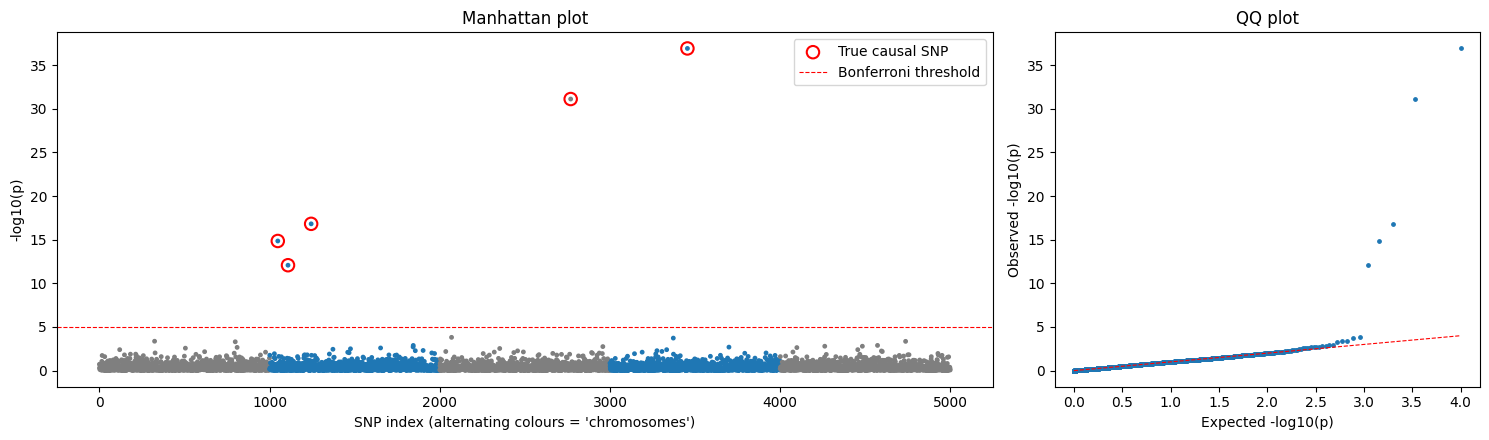

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
cols = ["#1f77b4", "#7f7f7f"]
ax[0].scatter(res.snp, -np.log10(res.p), s=6, c=[cols[c % 2] for c in res.chr])
c = res[res.is_causal]
ax[0].scatter(c.snp, -np.log10(c.p), s=80, facecolors="none", edgecolors="red", lw=1.5, label="True causal SNP")
ax[0].axhline(-np.log10(bonf), color="r", ls="--", lw=0.8, label="Bonferroni threshold")
ax[0].set_xlabel("SNP index (alternating colours = 'chromosomes')"); ax[0].set_ylabel("-log10(p)")
ax[0].set_title("Manhattan plot"); ax[0].legend()
obs = np.sort(-np.log10(res.p))
exp = -np.log10((np.arange(M, 0, -1) - 0.5) / M)
ax[1].scatter(exp, obs, s=6)
ax[1].plot([0, exp.max()], [0, exp.max()], "r--", lw=0.8)
ax[1].set_xlabel("Expected -log10(p)"); ax[1].set_ylabel("Observed -log10(p)"); ax[1].set_title("QQ plot")
plt.tight_layout(); plt.show()

      power  false_positives
N                           
200    0.16              0.1
500    0.62              0.0
1000   0.98              0.0
2000   1.00              0.0
5000   1.00              0.2


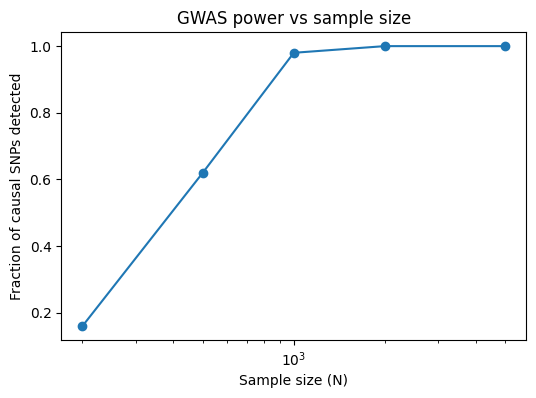

In [4]:
rows = []
for N in [200, 500, 1000, 2000, 5000]:
    for rep in range(10):
        Gs_, y_, cz, _ = simulate_gwas(N=N, seed=1000 + rep)
        _, p_ = association(Gs_, y_)
        sig = np.where(p_ < 0.05 / p_.size)[0]
        rows.append(dict(N=N, power=np.isin(cz, sig).mean(), false_positives=(~np.isin(sig, cz)).sum()))
pw = pd.DataFrame(rows).groupby("N").mean()
print(pw.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pw.index, pw.power, "o-")
ax.set_xscale("log"); ax.set_xlabel("Sample size (N)"); ax.set_ylabel("Fraction of causal SNPs detected")
ax.set_title("GWAS power vs sample size"); plt.show()